# Figure 2: CC between datasets

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

DATASETS = {
    'CHESS 2025-09-24':'chess_20250924',
    'ALS 2025-10-15':'als_20251015',
    'CHESS 2025-11-05':'chess_20251105',
    'ALS 2025-11-25':'als_20251125',
}

dataset_pairs = [
    ('ALS 2025-10-15','ALS 2025-11-25'),
    ('ALS 2025-10-15','CHESS 2025-09-24'),
    ('ALS 2025-10-15','CHESS 2025-11-05'),
    ('ALS 2025-11-25','CHESS 2025-09-24'),
    ('ALS 2025-11-25','CHESS 2025-11-05'),
    ('CHESS 2025-09-24','CHESS 2025-11-05'),
]

data = {}

# load all the merged data
for key1, key2 in dataset_pairs:
    df = pd.read_csv(f'source_data/fig2_cc_{DATASETS[key1]}_vs_{DATASETS[key2]}.csv').set_index('s')
    data[(key1,key2)] = df
    data[(key2,key1)] = df

ccstar_data = {}

# load all the merged data
for dset_key, dset_root in DATASETS.items():
    ccstar_data[dset_key] = pd.read_csv(f'source_data/fig2_cc_star_{dset_root}.csv').set_index('s')

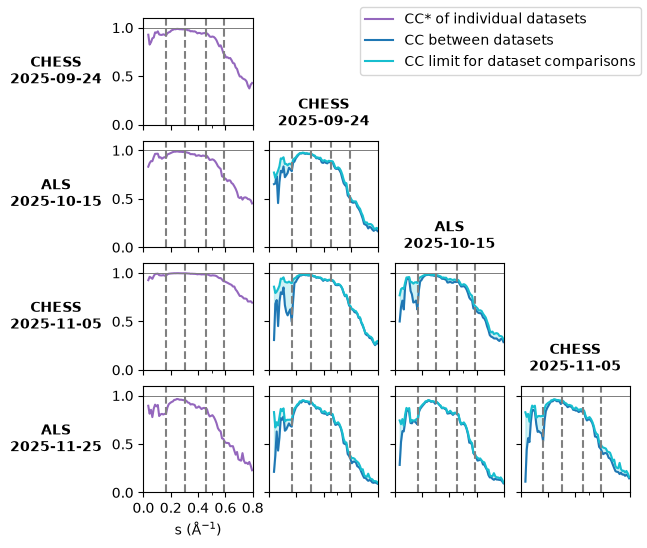

In [2]:
fig, axs = plt.subplots(4, 4, sharex=True, sharey=True, figsize=(6.5,5.5))

dataset_keys = list(DATASETS.keys())

for row in range(4):
    for col in range(4):
        if col > row:
            axs[row][col].axis('off')
            continue
        elif col == 0:
            df = ccstar_data[dataset_keys[row]]
            df['cc_star'].plot(ax=axs[row][col],color='tab:purple')
        else:
            df = data[(dataset_keys[row],dataset_keys[col-1])]
            df.plot(ax=axs[row][col],
                legend=False,
                color=['tab:blue','tab:cyan'],
                style=['-','-'],
            )
            axs[row][col].fill_between(df.index, df["cc"], df["cc_limit"], color="tab:cyan", alpha=0.2)
        for resol in [6,3.3,2.2,1.7]:
            axs[row][col].axvline(x=1/resol, color='gray', linestyle='--')
            axs[row][col].axhline(y=1, color='gray', linestyle='-', linewidth=0.5)

for col in range(1,4):
    row = col
    axs[row][col].text(
        0.5, 1.1,               # Top-left corner (5% from left, 95% from bottom)
        dataset_keys[col-1].replace(' ','\n'),
        transform=axs[row][col].transAxes,   # Locks coordinates to the axis frame (0.0 to 1.0)
        fontsize=10,
        fontweight='bold',
        verticalalignment='bottom',
        horizontalalignment='center',
    )
for row in range(4):
    col = 0
    axs[row][col].text(
        -.8, 0.5,               # Top-left corner (5% from left, 95% from bottom)
        dataset_keys[row].replace(' ','\n'),
        transform=axs[row][col].transAxes,   # Locks coordinates to the axis frame (0.0 to 1.0)
        fontsize=10,
        fontweight='bold',
        verticalalignment='center',
        horizontalalignment='center',
    )

for col, ax in enumerate(axs[-1]):
    ax.set_xlim([0,.8])
    ax.set_xticks([0,.2,.4,.6,.8])
    if col == 0:
        ax.set_xlabel('s (Å$^{-1}$)')
    else:
        ax.xaxis.label.set_visible(False)
        ax.tick_params(labelbottom=False, labelleft=False)

for ax in axs:
    ax[0].set_ylim([0,1.1])

#axs[1][0].set_ylabel('Correlation Coefficient (CC)')
axs[1][0].yaxis.set_label_coords(-.3, -.2) 
    
plt.tight_layout()
fig.subplots_adjust(hspace=0.15, wspace=0.15) 

handles, labels = [], []
for ax in [axs[-1][0],axs[-1][1]]:
    h, l = ax.get_legend_handles_labels()
    handles.extend(h)
    labels.extend(l)
# relabel
labels = [
    'CC* of individual datasets',
    'CC between datasets',
    'CC limit for dataset comparisons',
]
fig.legend(handles, labels, loc="upper right", ncols=1)
# # # save as svg, pdf, and high resolution png
plt.savefig("export/fig2_cc.svg", transparent=True, bbox_inches="tight")
plt.savefig("export/fig2_cc.pdf", transparent=True, bbox_inches="tight")
plt.savefig("export/fig2_cc.png", transparent=True, dpi=300)